# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [1]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### **1.1.1**
Load the dataset

In [2]:
# Load the data
df = pd.read_csv('/content/Car_Price_data.csv')
print("Data shape:",df.shape)
display(df.head())

Data shape: (15915, 23)


,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,...,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...",...,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,66.0,0,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1


## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>



### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [3]:
# Find the proportion of missing values in each column and handle if found
df.isnull().sum()/df.shape[0]

,0
make_model,0.0
body_type,0.0
price,0.0
vat,0.0
km,0.0
Type,0.0
Fuel,0.0
Gears,0.0
Comfort_Convenience,0.0
Entertainment_Media,0.0


In [4]:
df.duplicated().sum()

np.int64(1673)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  object 
 1   body_type            15915 non-null  object 
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  object 
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  object 
 6   Fuel                 15915 non-null  object 
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  object 
 9   Entertainment_Media  15915 non-null  object 
 10  Extras               15915 non-null  object 
 11  Safety_Security      15915 non-null  object 
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-null 

**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

Numerical predictors: Index(['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new',
       'Displacement_cc', 'Weight_kg', 'cons_comb'],
      dtype='object')
Number of numerical predictors: 9


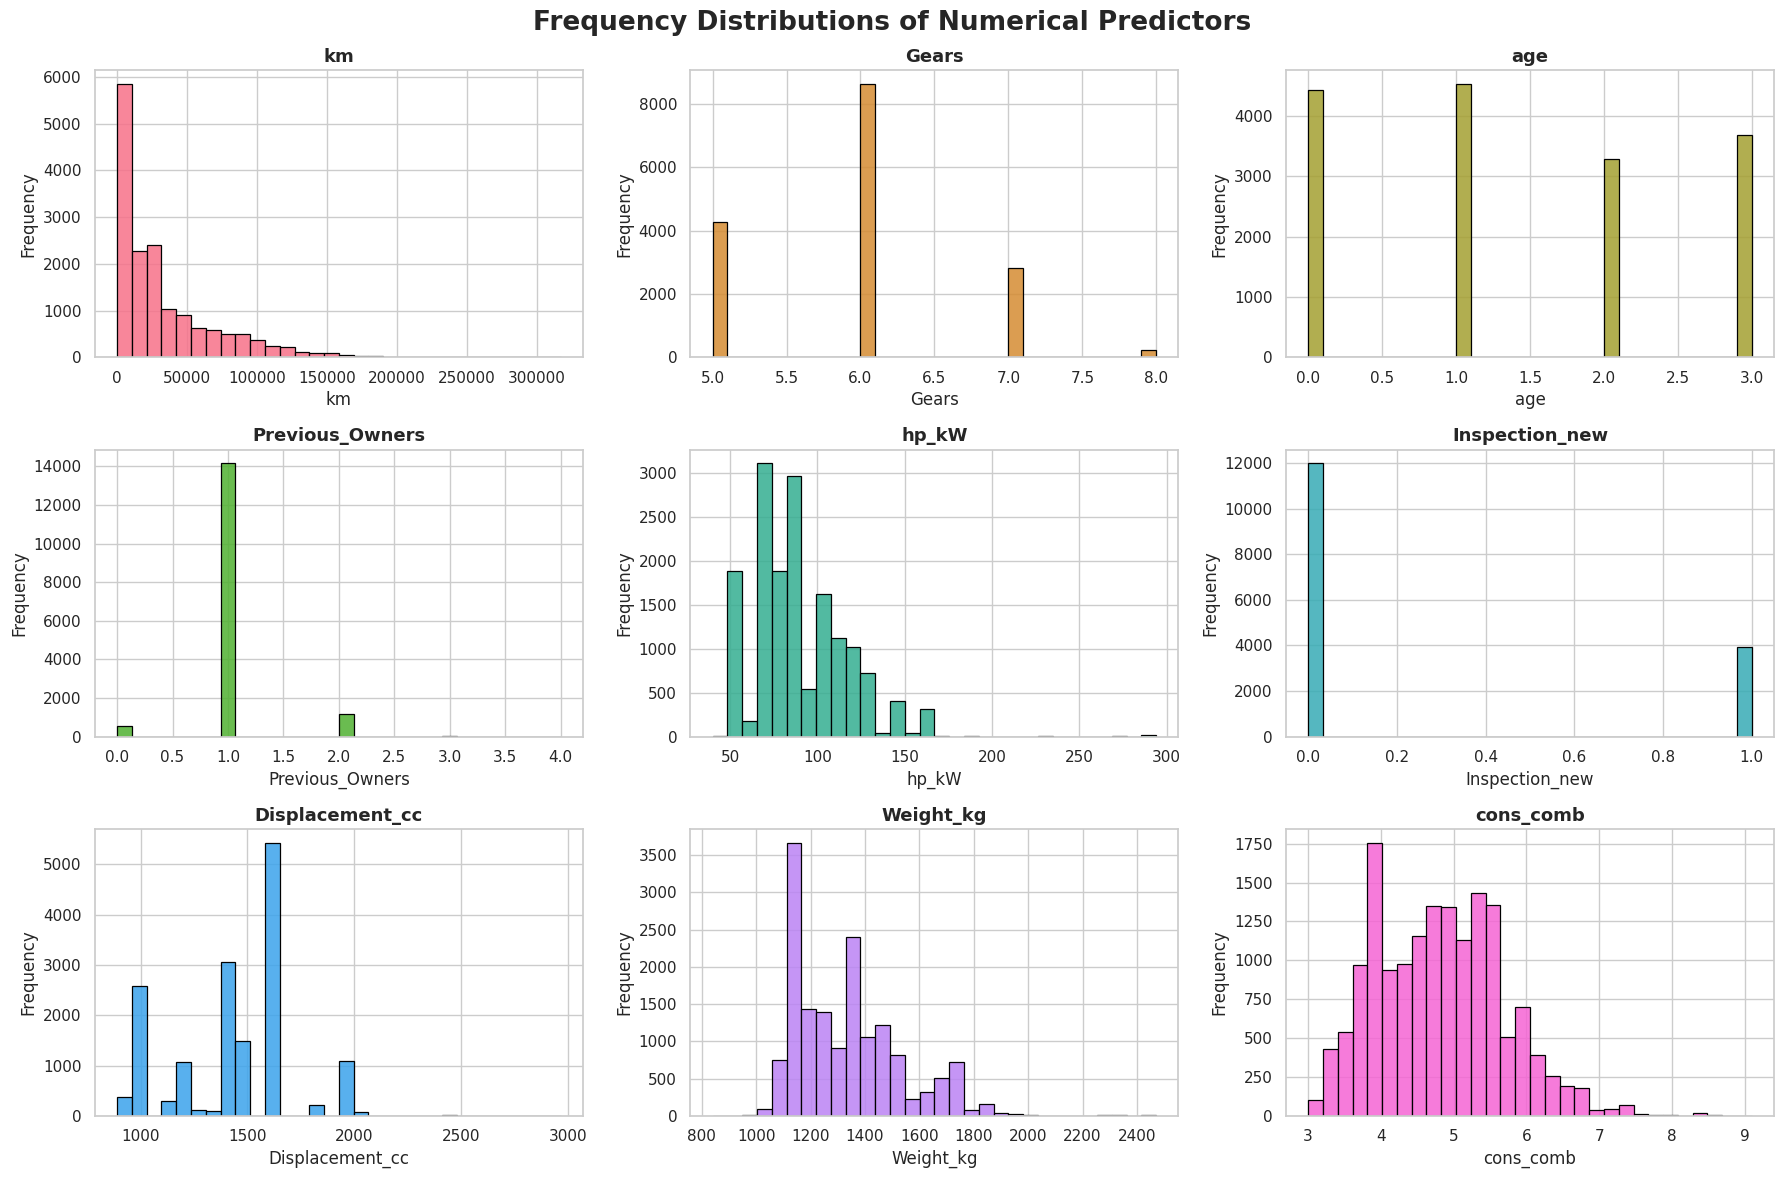

In [6]:
# Identify numerical features and plot histograms
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns
numerical_predictors = numerical_features.drop('price')
print("Numerical predictors:",numerical_predictors)
print("Number of numerical predictors:",len(numerical_predictors))
# plot graph
sns.set_theme(style="whitegrid", context="notebook")

# Different colors for each histogram
colors = sns.color_palette("husl", len(numerical_predictors))

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numerical_predictors):
    sns.histplot(data=df, x=col, bins=30,color=colors[i],edgecolor="black",alpha=0.85,ax=axes[i])
    axes[i].set_title(
        col,
        fontsize=13,
        fontweight="bold"
    )
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
plt.suptitle('Frequency Distributions of Numerical Predictors',fontsize =19,fontweight='bold')
plt.tight_layout()
plt.show()

#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

Categorical features: Index(['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Comfort_Convenience',
       'Entertainment_Media', 'Extras', 'Safety_Security', 'Paint_Type',
       'Upholstery_type', 'Gearing_Type', 'Drive_chain'],
      dtype='object')
Number of categorical features: 13
Regular Predictors: ['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain']
Number of regular categorical predictors: 9


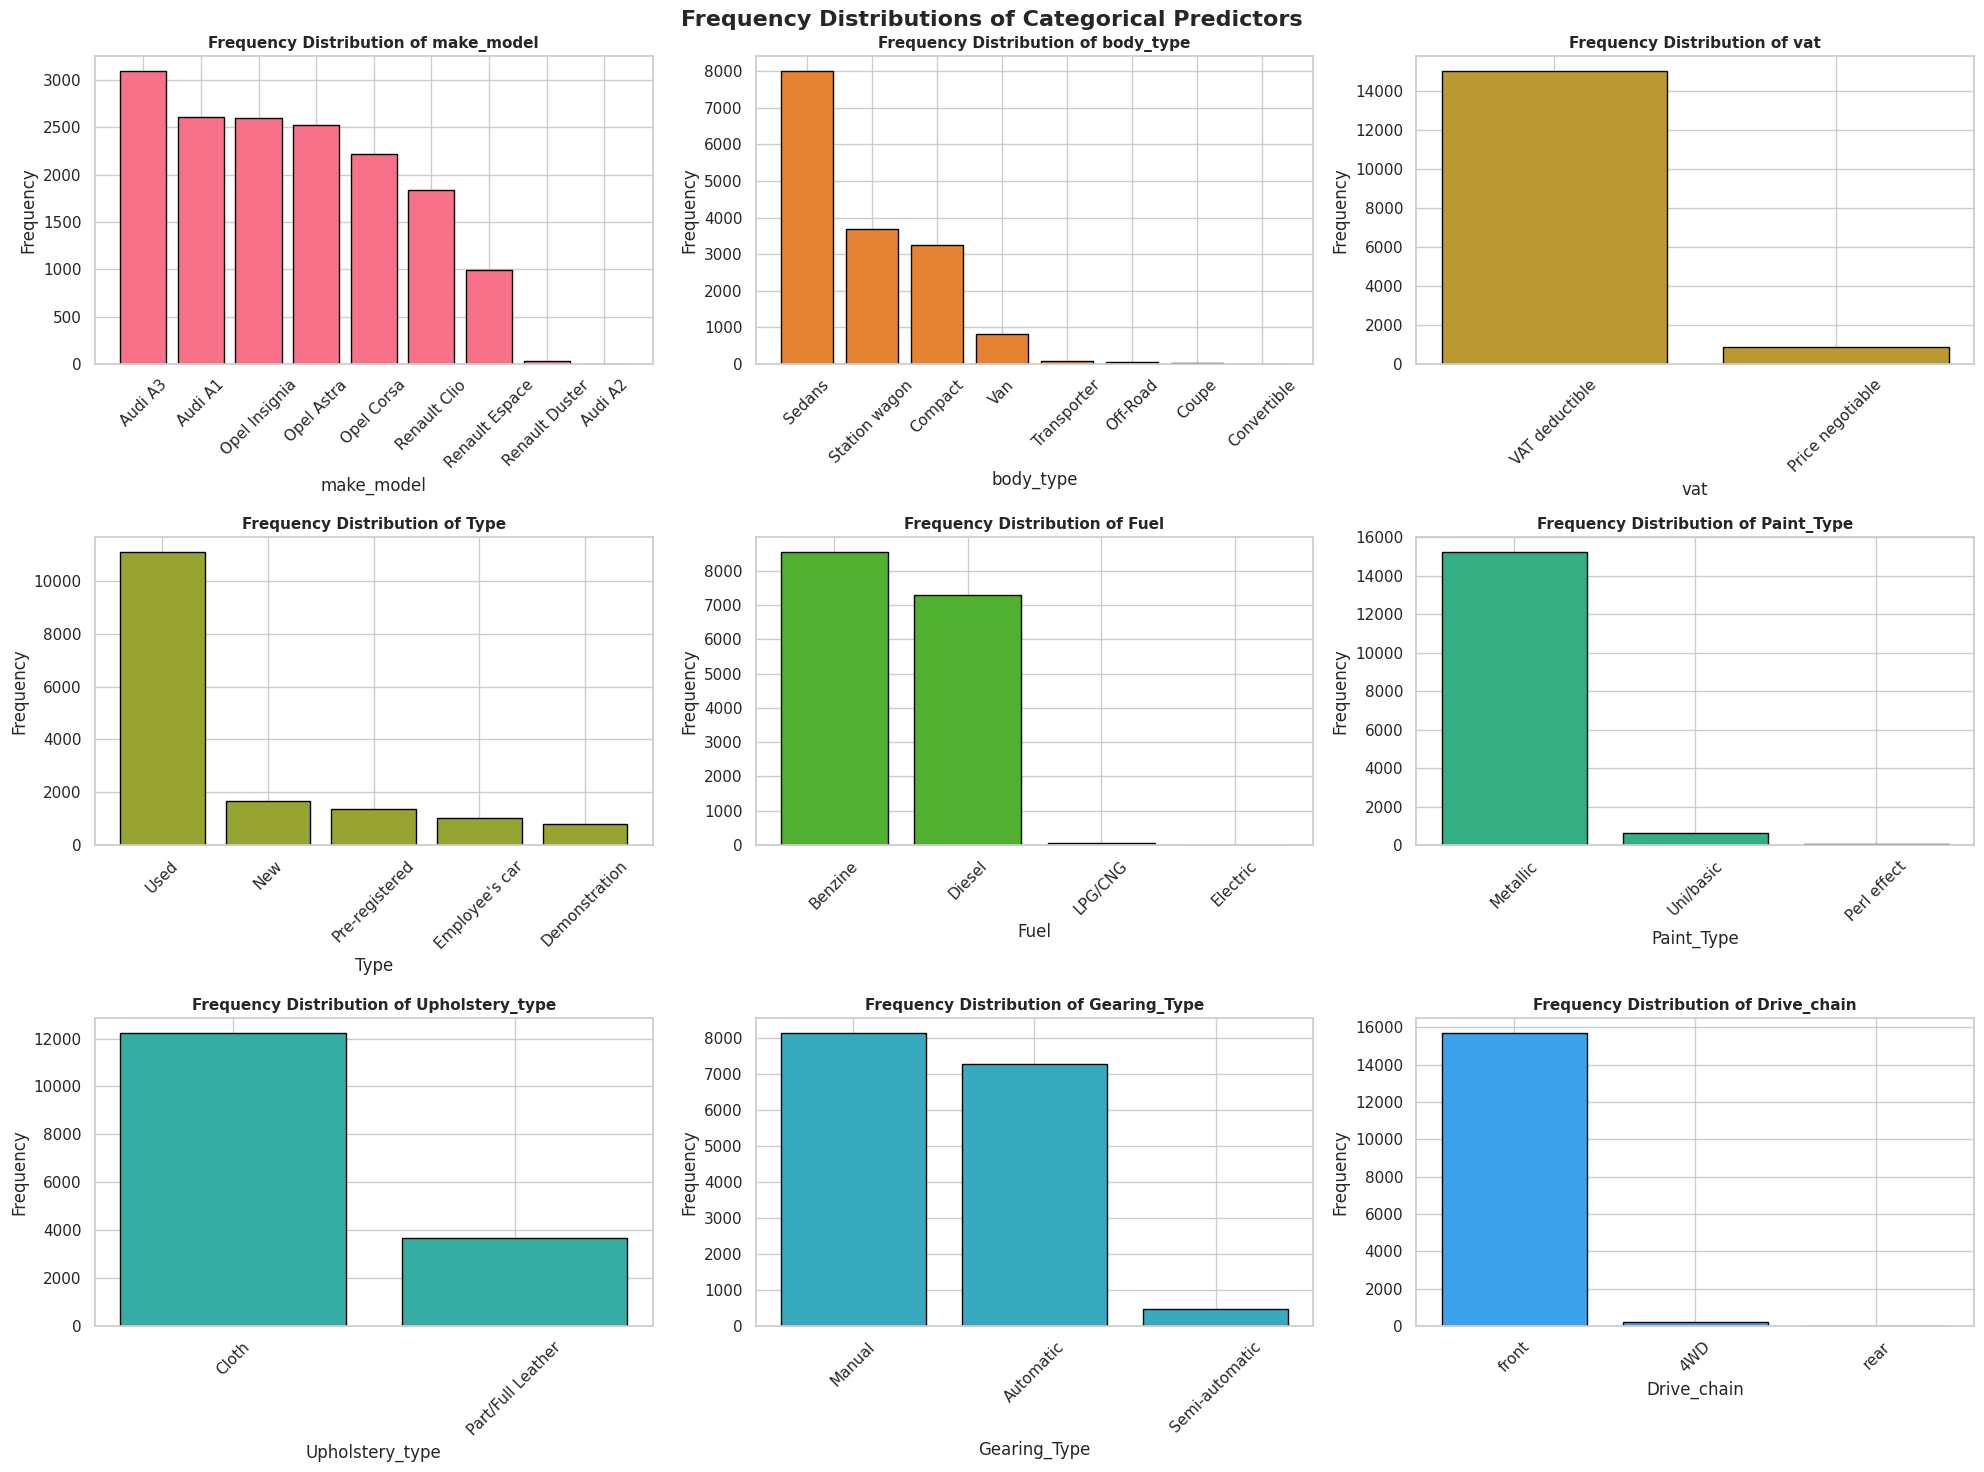

In [7]:
# Identify categorical columns and check their frequency distributions
categorical_features = df.select_dtypes(include=['object']).columns
print("Categorical features:",categorical_features)
print("Number of categorical features:",len(categorical_features))
# columns containing multiple featurs in one cell
multi_value_cols = ["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]
# Remaining categorical predictors
regular_categorical = [ col for col in categorical_features
                       if col not in multi_value_cols]
print("Regular Predictors:", regular_categorical)
print("Number of regular categorical predictors:",len(regular_categorical))
# plots of frequency distributions
sns.set_theme(style= "whitegrid")

fig, axes = plt.subplots(3,3,figsize=(20,15))
axes = axes.flatten()
colors = sns.color_palette("husl",12)
for i, col in enumerate(regular_categorical):
  counts = df[col].value_counts().head(10)
  axes[i].bar(
      counts.index.astype(str),
      counts.values,
      color = colors[i % len(colors)],
      edgecolor = 'black'
  )
  axes[i].set_title(
      f"Frequency Distribution of {col}",
      fontsize = 11,
      fontweight = 'bold'
  )
  axes[i].set_xlabel(col)
  axes[i].set_ylabel("Frequency")
  axes[i].tick_params(axis='x', rotation=45)
plt.suptitle('Frequency Distributions of Categorical Predictors',
             fontsize =16,
             fontweight="bold")
plt.tight_layout()
plt.show()

**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

In [8]:
# Fix columns as needed
# check category frequencies and percentages
for col in regular_categorical:
  print(f"\n{'='* 45}")
  print(f"column:",{col})
  counts = df[col].value_counts(dropna=False)
  percentages = (counts/len(df)*100).round(2)
  result = pd.DataFrame({'frequency': counts, 'Percentage': percentages})
  print(result.to_string())


column: {'make_model'}
                frequency  Percentage
make_model                           
Audi A3              3097       19.46
Audi A1              2614       16.42
Opel Insignia        2598       16.32
Opel Astra           2525       15.87
Opel Corsa           2216       13.92
Renault Clio         1839       11.56
Renault Espace        991        6.23
Renault Duster         34        0.21
Audi A2                 1        0.01

column: {'body_type'}
               frequency  Percentage
body_type                           
Sedans              8004       50.29
Station wagon       3677       23.10
Compact             3240       20.36
Van                  817        5.13
Transporter           88        0.55
Off-Road              56        0.35
Coupe                 25        0.16
Convertible            8        0.05

column: {'vat'}
                  frequency  Percentage
vat                                    
VAT deductible        15044       94.53
Price negotiable        871 

In [9]:

# Keep the original dataset unchanged
df_clean = df.copy()
# Merge rare categories in regular categorical predictors
# Exception: Type has meaningful business categories
rare_threshold = 0.01  # 1%

for col in regular_categorical:
    if col == 'Type':
        continue

    proportions = df_clean[col].value_counts(normalize=True)
    rare_categories = proportions[proportions < rare_threshold].index

    df_clean[col] = df_clean[col].where(~df_clean[col].isin(rare_categories),'Other')

    if len(rare_categories) > 0:
        print(f"\n{col}:")
        print("Merged categories:", list(rare_categories))

print("\nCleaning completed.")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)



make_model:
Merged categories: ['Renault Duster', 'Audi A2']

body_type:
Merged categories: ['Transporter', 'Off-Road', 'Coupe', 'Convertible']

Fuel:
Merged categories: ['LPG/CNG', 'Electric']

Paint_Type:
Merged categories: ['Perl effect']

Drive_chain:
Merged categories: ['rear']

Cleaning completed.
Original shape: (15915, 23)
Cleaned shape: (15915, 23)


In [10]:
# Verify the updated category frequencies
for col in ['make_model', 'body_type', 'Fuel', 'Paint_Type', 'Drive_chain', 'Type']:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts())


--- make_model ---
make_model
Audi A3           3097
Audi A1           2614
Opel Insignia     2598
Opel Astra        2525
Opel Corsa        2216
Renault Clio      1839
Renault Espace     991
Other               35
Name: count, dtype: int64

--- body_type ---
body_type
Sedans           8004
Station wagon    3677
Compact          3240
Van               817
Other             177
Name: count, dtype: int64

--- Fuel ---
Fuel
Benzine    8548
Diesel     7298
Other        69
Name: count, dtype: int64

--- Paint_Type ---
Paint_Type
Metallic     15246
Uni/basic      637
Other           32
Name: count, dtype: int64

--- Drive_chain ---
Drive_chain
front    15707
4WD        204
Other        4
Name: count, dtype: int64

--- Type ---
Type
Used              11095
New                1649
Pre-registered     1364
Employee's car     1011
Demonstration       796
Name: count, dtype: int64


#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

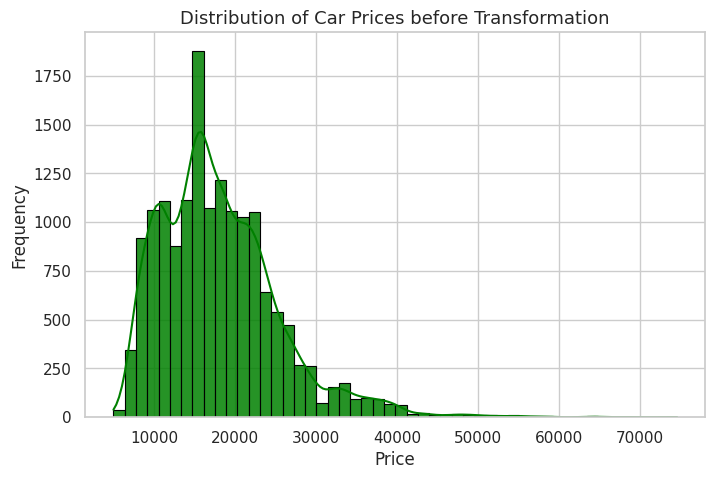

Price skewnes before transformation: 1.2361694128996692


In [11]:
# Plot histograms for target feature
target = 'price'
plt.figure(figsize=(8,5))
sns.histplot(data=df_clean, x=target, bins=50,color='green',edgecolor="black",alpha=0.85,kde= True)
plt.title('Distribution of Car Prices before Transformation',fontsize =13)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

# check skewness
print("Price skewnes before transformation:",df_clean[target].skew())


The target variable seems to be skewed. Perform suitable transformation on the target.

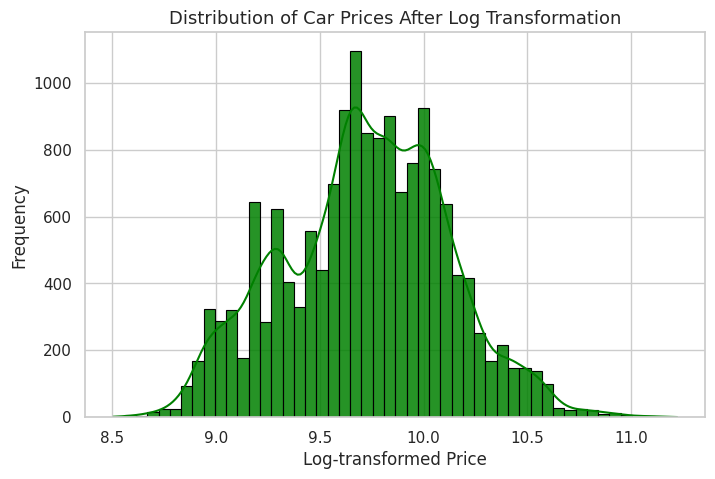

Price skewnes after transformation: -0.0314736417467197


In [12]:
# Transform the target feature
target = 'price'
# transform the target variable
df_clean[target] = np.log1p(df_clean[target])
# Plot the transformed histogram for target feature
plt.figure(figsize=(8,5))
sns.histplot(data=df_clean, x=target, bins=50,color='green',edgecolor="black",alpha=0.85,kde= True)
plt.title('Distribution of Car Prices After Log Transformation',fontsize =13)
plt.xlabel('Log-transformed Price')
plt.ylabel('Frequency')
plt.show()

# check skewness
print("Price skewnes after transformation:",df_clean[target].skew())

### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

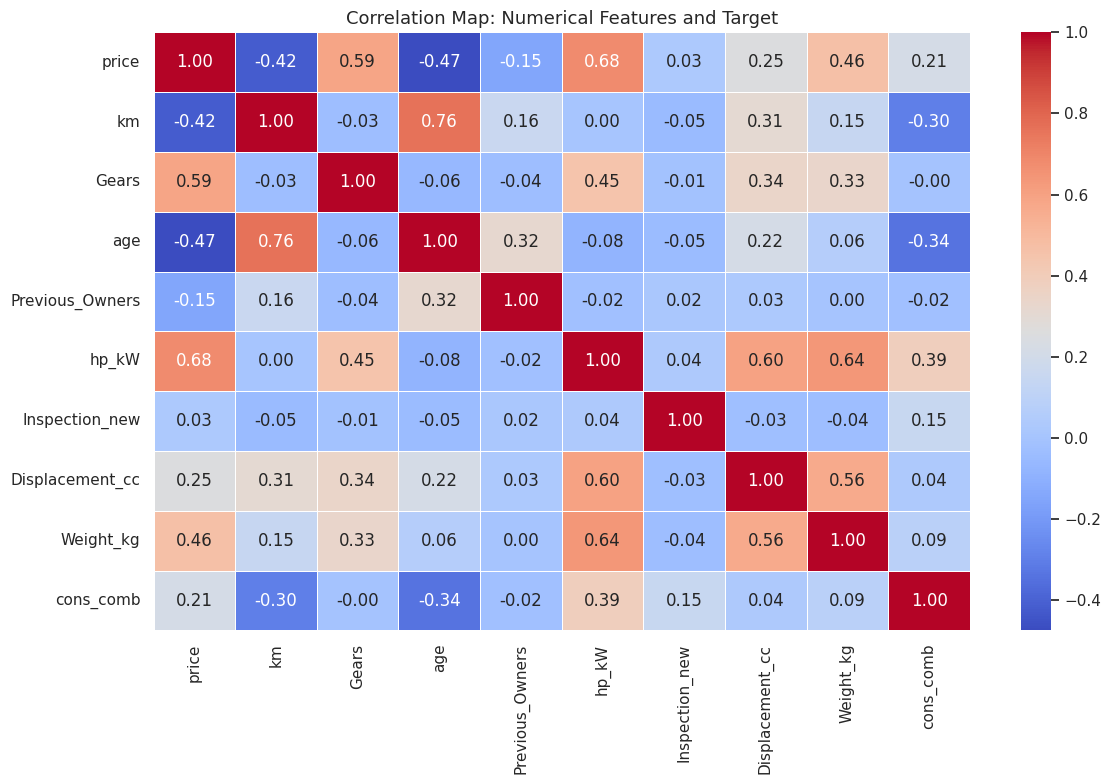

In [13]:
# Visualise correlation
numerical_df = df_clean.select_dtypes(include= np.number)
# calculate correlation matrix
corr_matrix = numerical_df.corr()
# plot correalation heatpmap
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix,annot=True, cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('Correlation Map: Numerical Features and Target',fontsize =13)
plt.tight_layout()
plt.show()

#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.

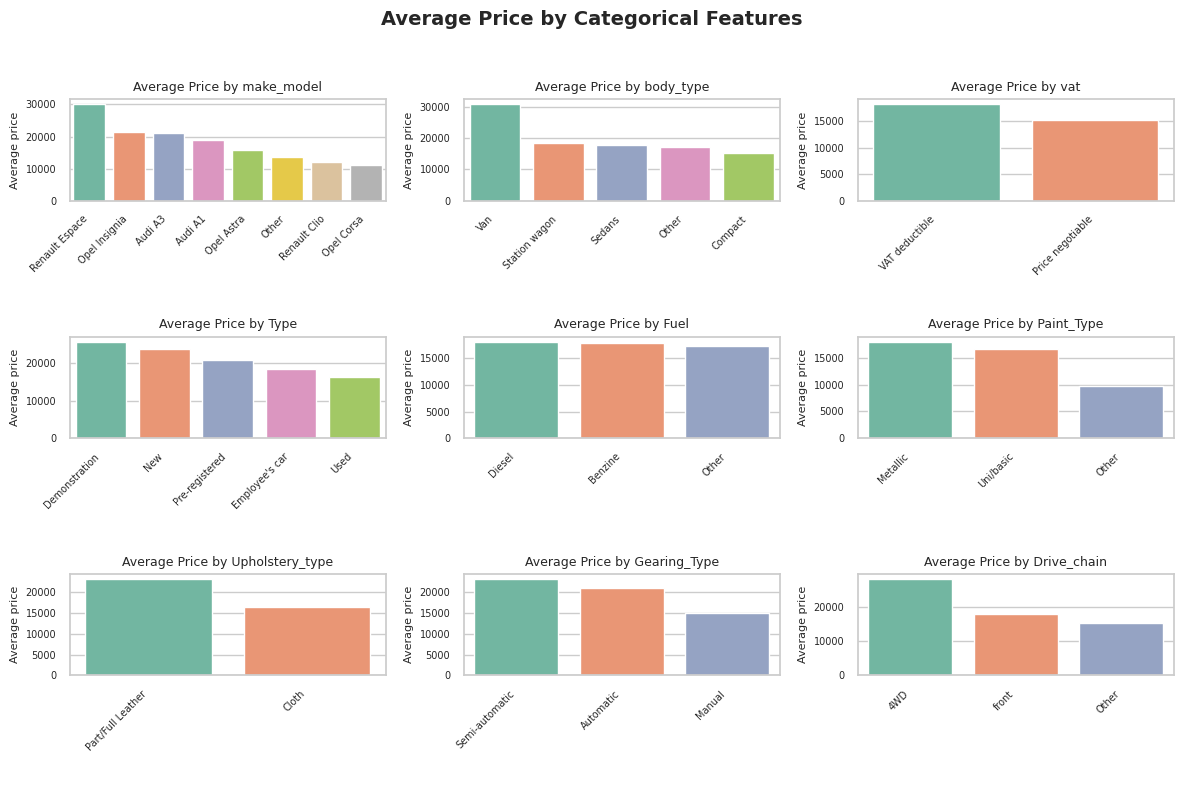

In [14]:
# Comparing average values of target for different categories
df_analysis = df_clean.copy()
df_analysis['price'] = df['price']
# select categorical features
categorical_features = ['make_model','body_type','vat','Type','Fuel','Paint_Type','Upholstery_type','Gearing_Type','Drive_chain']
# plot average price for each category
fig,axes = plt.subplots(3,3,figsize=(12,8))
axes = axes.flatten()
for ax,col in zip(axes,categorical_features):
  avg_price = df_analysis.groupby(col,observed=True)['price'].mean().sort_values(ascending=False)
  sns.barplot(x=avg_price.index,
              y=avg_price.values,
              hue=avg_price.index,
              ax=ax,
              palette='Set2',
              legend=False)
  ax.set_title(f"Average Price by {col}",fontsize=9)
  ax.set_xlabel(" ")
  ax.set_ylabel("Average price",fontsize=8)
  ax.tick_params(axis='x',  labelrotation=45,labelsize=7)
  ax.tick_params(axis='y', labelsize=7)
  for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')
fig.suptitle('Average Price by Categorical Features', fontsize=14,fontweight='bold')
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()


### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

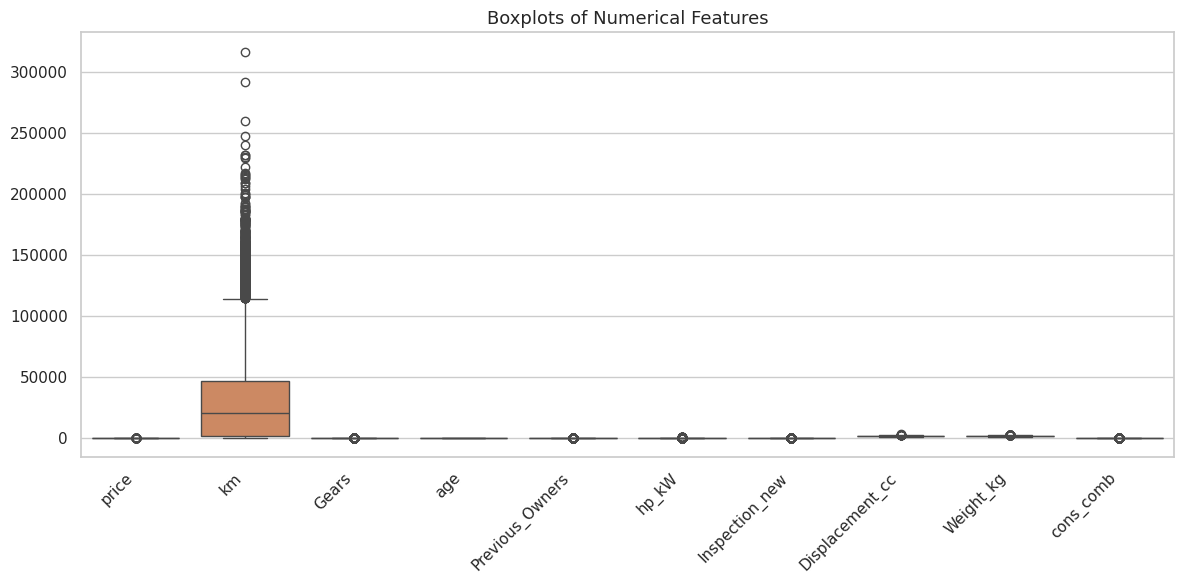

In [15]:
# Outliers present in each column
numerical_cols = df_clean.select_dtypes(include='number').columns
# plot boxplots
plt.figure(figsize=(12,6))
sns.boxplot(data= df_clean[numerical_cols])
plt.xticks(rotation=45,ha= 'right')
plt.title('Boxplots of Numerical Features',fontsize =13)
plt.tight_layout()
plt.show()


In [16]:
numerical_cols = df_clean.select_dtypes(include='number').columns
results = []

for col in numerical_cols:
    s = df_clean[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (s < lower) | (s > upper)

    results.append({
        'Feature': col,
        'Outlier_Count': int(mask.sum()),
        'Outlier_%': round(mask.mean() * 100, 2),
        'Min': s.min(),
        'Max': s.max(),
        'IQR_Lower': round(lower, 2),
        'IQR_Upper': round(upper, 2),
        'Flagged_Min': s[mask].min() if mask.any() else None,
        'Flagged_Max': s[mask].max() if mask.any() else None
    })

outlier_summary = pd.DataFrame(results)

display(
    outlier_summary.sort_values(
        'Outlier_Count', ascending=False
    ).reset_index(drop=True)
)

,Feature,Outlier_Count,Outlier_%,Min,Max,IQR_Lower,IQR_Upper,Flagged_Min,Flagged_Max
0,Inspection_new,3932,24.71,0.000000,1.000000,0.00,0.00,1.000000,1.000000
1,Previous_Owners,1757,11.04,0.000000,4.000000,1.00,1.00,0.000000,4.000000
2,km,689,4.33,0.000000,317000.000000,-65548.75,114369.25,114550.000000,317000.000000
3,hp_kW,361,2.27,40.000000,294.000000,10.50,158.50,162.000000,294.000000
4,Gears,225,1.41,5.000000,8.000000,3.50,7.50,8.000000,8.000000
5,cons_comb,125,0.79,3.000000,9.100000,2.15,7.35,7.400000,9.100000
6,Weight_kg,87,0.55,840.000000,2471.000000,704.50,1932.50,1939.000000,2471.000000
7,price,71,0.45,8.507345,11.219909,8.66,10.79,8.507345,11.219909
8,Displacement_cc,21,0.13,890.000000,2967.000000,675.50,2151.50,2480.000000,2967.000000
9,age,0,0.00,0.000000,3.000000,-3.00,5.00,NaN,NaN


#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

In [17]:
# Handle outliers
outliers_col = ['km','hp_kW','cons_comb','Weight_kg','price','Displacement_cc']
for col in outliers_col:
  q1 = df_clean[col].quantile(0.25)
  q3 = df_clean[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr

  df_clean[col] = df_clean[col].clip(lower_bound, upper_bound)
print("Outlier capping completed")

Outlier capping completed


In [18]:
for col in outliers_col:
    print(
        col,
        "Min:", df_clean[col].min(),
        "Max:", df_clean[col].max()
    )

km Min: 0.0 Max: 114369.25
hp_kW Min: 40.0 Max: 158.5
cons_comb Min: 3.0 Max: 7.350000000000001
Weight_kg Min: 840.0 Max: 1932.5
price Min: 8.661510905474003 Max: 10.793953579695703
Displacement_cc Min: 890.0 Max: 2151.5


**Outlier Handling**

Potential outliers in selected numerical features were handled using the IQR method. The lower and upper limits were calculated, and extreme values were capped using the `clip()` function instead of deleting observations. This approach retains the dataset records while limiting the influence of extreme values. Binary and discrete features were not capped because the IQR method may not be appropriate for them.

### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

In [19]:
# Check duplicate rows and their impact
duplicate_mask = df_clean.duplicated()
print("Total rows:", len(df_clean))
print("Duplicate rows:", duplicate_mask.sum())
print("Unique rows:", len(df_clean) - duplicate_mask.sum())

# Display a few duplicate records
display(df_clean[df_clean.duplicated(keep=False)].head(10))


Total rows: 15915
Duplicate rows: 1676
Unique rows: 14239


,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,...,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
2,Audi A1,Sedans,9.591581,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
5,Audi A1,Sedans,9.621854,VAT deductible,63668.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,1.0,85.0,0,Metallic,Part/Full Leather,Automatic,1598.0,1135.0,front,3.5
15,Audi A1,Sedans,9.836332,VAT deductible,27000.0,Employee's car,Diesel,7.0,"Air conditioning,Armrest,Cruise control,Electr...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1275.0,front,3.7
19,Audi A1,Sedans,9.825580,VAT deductible,13406.0,Used,Diesel,7.0,"Air conditioning,Armrest,Auxiliary heating,Ele...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
81,Audi A1,Sedans,9.825580,VAT deductible,13406.0,Used,Diesel,7.0,"Air conditioning,Armrest,Auxiliary heating,Ele...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
123,Audi A1,Sedans,9.836332,VAT deductible,27000.0,Employee's car,Diesel,7.0,"Air conditioning,Armrest,Cruise control,Electr...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1275.0,front,3.7
133,Audi A1,Compact,9.816513,VAT deductible,4800.0,Employee's car,Benzine,7.0,"Air conditioning,Electrical side mirrors,Hill ...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,70.0,1,Metallic,Cloth,Automatic,999.0,1165.0,front,4.4
136,Audi A1,Compact,9.816513,VAT deductible,4800.0,Employee's car,Benzine,7.0,"Air conditioning,Electrical side mirrors,Hill ...","Bluetooth,CD player,Hands-free equipment,MP3,O...",...,1.0,70.0,1,Metallic,Cloth,Automatic,999.0,1165.0,front,4.4
287,Audi A1,Sedans,9.621854,VAT deductible,63668.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,1.0,85.0,0,Metallic,Part/Full Leather,Automatic,1598.0,1135.0,front,3.5
291,Audi A1,Sedans,9.621854,VAT deductible,63668.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",...,1.0,85.0,0,Metallic,Part/Full Leather,Automatic,1598.0,1135.0,front,3.5


In [20]:
# Fix/create columns as needed
# remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()
print("Shape after removing duplicates:",df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Shape after removing duplicates: (14239, 23)
Remaining duplicate rows: 0


#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [21]:
# Check unique values in each feature spec column
feature_spec_cols = ['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']
for col in feature_spec_cols:
  print("\n{col}")
  print("Unique combinations:",df_clean[col].nunique())
  print("Sample values:")
  display(df_clean[col].dropna().head(3))


{col}
Unique combinations: 6196
Sample values:


,Comfort_Convenience
0,"Air conditioning,Armrest,Automatic climate con..."
1,"Air conditioning,Automatic climate control,Hil..."
2,"Air conditioning,Cruise control,Electrical sid..."



{col}
Unique combinations: 346
Sample values:


,Entertainment_Media
0,"Bluetooth,Hands-free equipment,On-board comput..."
1,"Bluetooth,Hands-free equipment,On-board comput..."
2,"MP3,On-board computer"



{col}
Unique combinations: 659
Sample values:


,Extras
0,"Alloy wheels,Catalytic Converter,Voice Control"
1,"Alloy wheels,Sport seats,Sport suspension,Voic..."
2,"Alloy wheels,Voice Control"



{col}
Unique combinations: 4442
Sample values:


,Safety_Security
0,"ABS,Central door lock,Daytime running lights,D..."
1,"ABS,Central door lock,Central door lock with r..."
2,"ABS,Central door lock,Daytime running lights,D..."


In [22]:
from collections import Counter
for col in feature_spec_cols:
    feature_counts = Counter()

    for value in df_clean[col].dropna():
        features = [x.strip() for x in value.split(',') if x.strip()]
        feature_counts.update(set(features))

    print(f"\n{col}")
    print("Total individual features:", len(feature_counts))
    print("Top 10 features:", feature_counts.most_common(10))



Comfort_Convenience
Total individual features: 38
Top 10 features: [('Air conditioning', 13591), ('Power windows', 13309), ('Electrical side mirrors', 11307), ('Multi-function steering wheel', 10649), ('Cruise control', 10443), ('Park Distance Control', 9639), ('Parking assist system sensors rear', 9176), ('Leather steering wheel', 8884), ('Start-stop system', 8431), ('Automatic climate control', 8407)]

Entertainment_Media
Total individual features: 10
Top 10 features: [('Radio', 11859), ('On-board computer', 11852), ('Bluetooth', 11378), ('Hands-free equipment', 9345), ('USB', 8053), ('MP3', 5705), ('CD player', 4613), ('Digital radio', 2076), ('Sound system', 1971), ('Television', 39)]

Extras
Total individual features: 17
Top 10 features: [('Alloy wheels', 12492), ('Voice Control', 3987), ('Touch screen', 3747), ('Sport seats', 2884), ('Roof rack', 2794), ('Catalytic Converter', 2090), ('Sport suspension', 1438), ('Sport package', 1065), ('Trailer hitch', 632), ('Shift paddles', 4

Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [23]:
# Check feature frequency before dropping features
for col in feature_spec_cols:
    feature_counts = {}

    for value in df_clean[col].dropna():
        features = set(x.strip() for x in value.split(',') if x.strip())
        for feature in features:
            feature_counts[feature] = feature_counts.get(feature, 0) + 1

    total_cars = len(df_clean)

    print(f"\n{col}")
    print("Features present in more than 95% of cars:")
    print({k: v for k, v in feature_counts.items()
        if v / total_cars > 0.95})

    print("Features present in fewer than 1% of cars:")
    print({k: v for k, v in feature_counts.items()
         if v / total_cars < 0.01})



Comfort_Convenience
Features present in more than 95% of cars:
{'Air conditioning': 13591}
Features present in fewer than 1% of cars:
{'Air suspension': 66, 'Wind deflector': 41, 'Leather seats': 48, 'Windshield': 12, 'Electric Starter': 1}

Entertainment_Media
Features present in more than 95% of cars:
{}
Features present in fewer than 1% of cars:
{'Television': 39}

Extras
Features present in more than 95% of cars:
{}
Features present in fewer than 1% of cars:
{'Handicapped enabled': 52, 'Tuned car': 13, 'Sliding door': 3, 'Right hand drive': 3}

Safety_Security
Features present in more than 95% of cars:
{}
Features present in fewer than 1% of cars:
{'Night view assist': 75}


In [24]:
# Drop features from df
features_to_drop = {'Comfort_Convenience': ['Air conditioning','Air suspension','Wind deflector','Leather seats','Windshield','Electric Starter'],
                    'Entertainment_Media': ['Television'],
                    'Extras': ['Handicapped enabled','Tuned car','Sliding door','Right hand drive'],
                    'Safety_Security': ['Night view assist']}
for col, drop_features in features_to_drop.items():
    df_clean[col] = df_clean[col].apply(
        lambda x: ', '.join(
            feature.strip()
            for feature in x.split(',')
            if feature.strip() not in drop_features
        )
    )
print("Selected common and rare features removed")

Selected common and rare features removed


#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [25]:
# Encode features
categorical_cols = ['make_model','body_type','vat','Type','Fuel','Paint_Type','Upholstery_type','Gearing_Type','Drive_chain']
df_encoded = pd.get_dummies(df_clean,
                            columns= categorical_cols,
                            drop_first=True,
                            dtype= int)
print("Shape before encoding:",df_clean.shape)
print("Shape after encoding:",df_encoded.shape)
print("\n Sample encoded columns:")
display(df_encoded.head())

Shape before encoding: (14239, 23)
Shape after encoding: (14239, 39)

 Sample encoded columns:


,price,km,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,...,Type_Used,Fuel_Diesel,Fuel_Other,Paint_Type_Other,Paint_Type_Uni/basic,Upholstery_type_Part/Full Leather,Gearing_Type_Manual,Gearing_Type_Semi-automatic,Drive_chain_Other,Drive_chain_front
0,9.665928,56013.0,7.0,"Armrest, Automatic climate control, Cruise con...","Bluetooth, Hands-free equipment, On-board comp...","Alloy wheels, Catalytic Converter, Voice Control","ABS, Central door lock, Daytime running lights...",3.0,2.0,66.0,...,1,1,0,0,0,0,0,0,0,1
1,9.581973,80000.0,7.0,"Automatic climate control, Hill Holder, Leathe...","Bluetooth, Hands-free equipment, On-board comp...","Alloy wheels, Sport seats, Sport suspension, V...","ABS, Central door lock, Central door lock with...",2.0,1.0,141.0,...,1,0,0,0,0,0,0,0,0,1
2,9.591581,83450.0,7.0,"Cruise control, Electrical side mirrors, Hill ...","MP3, On-board computer","Alloy wheels, Voice Control","ABS, Central door lock, Daytime running lights...",3.0,1.0,85.0,...,1,1,0,0,0,0,0,0,0,1
3,9.581973,73000.0,6.0,"Armrest, Auxiliary heating, Electrical side mi...","Bluetooth, CD player, Hands-free equipment, MP...","Alloy wheels, Sport seats, Voice Control","ABS, Alarm system, Central door lock with remo...",3.0,1.0,66.0,...,1,1,0,0,0,0,0,0,0,1
4,9.728598,16200.0,7.0,"Armrest, Automatic climate control, Electrical...","Bluetooth, CD player, Hands-free equipment, MP...","Alloy wheels, Sport package, Sport suspension,...","ABS, Central door lock, Driver-side airbag, El...",3.0,1.0,66.0,...,1,1,0,0,0,0,0,0,0,1


In [26]:

# Binary encode the car specification features
for col in feature_spec_cols:
    feature_lists = df_encoded[col].fillna('').apply(lambda x: [item.strip() for item in x.split(',') if item.strip()])
    all_features = sorted({feature
        for features in feature_lists
        for feature in features})

    for feature in all_features:
        new_col = f"{col}_{feature}"
        df_encoded[new_col] = feature_lists.apply(lambda features: int(feature in features))
    df_encoded.drop(columns=col, inplace=True)

print("Final shape:", df_encoded.shape)
print("Remaining text specification columns:",
      [col for col in feature_spec_cols if col in df_encoded.columns])
print("Remaining duplicate rows:", df_encoded.duplicated().sum())


Final shape: (14239, 117)
Remaining text specification columns: []
Remaining duplicate rows: 1


In [27]:
df_encoded = df_encoded.drop_duplicates().copy()
print(df_encoded.shape)

(14238, 117)


#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [28]:
# Split data
from sklearn.model_selection import train_test_split
# seprate predictors and target
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']
# split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Shape of X_train:",X_train.shape)
print("Shape of X_test:",X_test.shape)
print("Shape of y_train:",y_train.shape)
print("Shape of y_test:",y_test.shape)

Shape of X_train: (11390, 116)
Shape of X_test: (2848, 116)
Shape of y_train: (11390,)
Shape of y_test: (2848,)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [29]:
# Scale features
from sklearn.preprocessing import MinMaxScaler
# scale features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:",X_train_scaled.shape)
print("Scaled testing shape:",X_test_scaled.shape)

Scaled training shape: (11390, 116)
Scaled testing shape: (2848, 116)


## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [30]:
from sklearn.linear_model import LinearRegression
# Initialise and train model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled,y_train)
print("Linear Regression model trained successfully")

Linear Regression model trained successfully


In [31]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
# make predictions
y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred = lr_model.predict(X_test_scaled)
# Evaluate the model's performance
print("TEST MSE:",mean_squared_error(y_test,y_test_pred))
print("TEST RMSE",np.sqrt(mean_squared_error(y_test,y_test_pred)))
print("TEST MAE:",mean_absolute_error(y_test,y_test_pred))
print("TEST R2:",r2_score(y_test,y_test_pred))

TEST MSE: 0.011448661827020798
TEST RMSE 0.10699841974076439
TEST MAE: 0.07724636616139505
TEST R2: 0.9275245535248705


#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

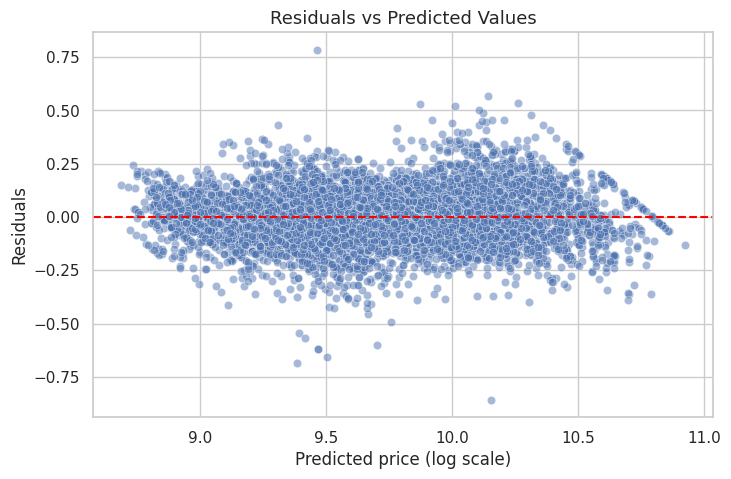

In [32]:
# Linearity check: Plot residuals vs fitted values
# check residuals
residuals = y_train - y_train_pred
# Plot residuals vs fitted values
plt.figure(figsize=(8,5))
sns.scatterplot(x= y_train_pred,y= residuals,alpha=0.5)
plt.axhline(y=0,color='red', linestyle='--')
plt.title('Residuals vs Predicted Values',fontsize =13)
plt.xlabel('Predicted price (log scale)')
plt.ylabel('Residuals')
plt.show()


Check normality in residual distribution

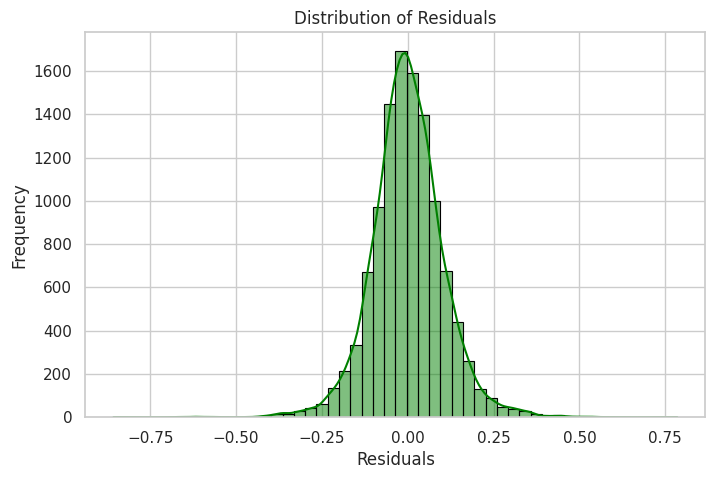

In [33]:
# Check the normality of residuals by plotting their distribution
plt.figure(figsize=(8,5))
sns.histplot(residuals,bins= 50,color='green',edgecolor="black",kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()


**Residual Analysis and Linear Regression Assumptions**

The residuals vs predicted values plot shows that most residuals are randomly scattered around the zero line, with no strong curved pattern. This suggests that the linearity assumption is reasonably satisfied. However, the spread of residuals varies across predicted values, indicating that constant variance may not be fully satisfied.

The residual distribution is approximately bell-shaped and centered around zero, suggesting that the normality assumption is reasonably satisfied, although some extreme residuals are present.

Overall, the baseline linear regression model performs well, but some deviations from the regression assumptions may exist.

Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [34]:
# Check for multicollinearity and handle
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(pd.DataFrame(X_train_scaled, columns=X_train.columns))
vif_data = pd.DataFrame({
    "features": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])]
})
vif_data = vif_data[vif_data.features != 'const'].sort_values("VIF", ascending=False)
display(vif_data.head(15))

,features,VIF
16,make_model_Renault Espace,10.715019
5,hp_kW,8.674154
13,make_model_Opel Insignia,7.030728
7,Displacement_cc,7.029740
26,Fuel_Diesel,6.972539
20,body_type_Van,6.961282
25,Type_Used,5.405883
12,make_model_Opel Corsa,5.372336
58,Comfort_Convenience_Parking assist system sens...,4.877495
8,Weight_kg,4.865873


**VIF Analysis and Handling**

Features with high VIF are mainly one-hot encoded make_model/body_type dummies and engine-related variables (hp_kW, Displacement_cc, Weight_kg), which are naturally correlated. These features were retained because they are informative for price, and Ridge and Lasso regularisation are designed to handle multicollinearity by shrinking coefficients.

### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [35]:
# List of alphas to tune for Ridge regularisation
Alphas = [0.001, 0.01, 0.1, 1, 10, 100,1000]
print("Alpha values:", Alphas)


Alpha values: [0.001, 0.01, 0.1, 1, 10, 100, 1000]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [36]:
# Applying Ridge regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import numpy as np
# Initialise Ridge regression model
train_score = []
test_score = []
ridge_models =[]
for alpha in Alphas:
  ridge_model = Ridge(alpha=alpha)
  ridge_model.fit(X_train_scaled,y_train)
  y_train_pred = ridge_model.predict(X_train_scaled)
  y_test_pred = ridge_model.predict(X_test_scaled)
  train_score.append(r2_score(y_train,y_train_pred))
  test_score.append(r2_score(y_test,y_test_pred))
  ridge_models.append(ridge_model)
print("Ridge model trained for all alpha vlaues")

Ridge model trained for all alpha vlaues


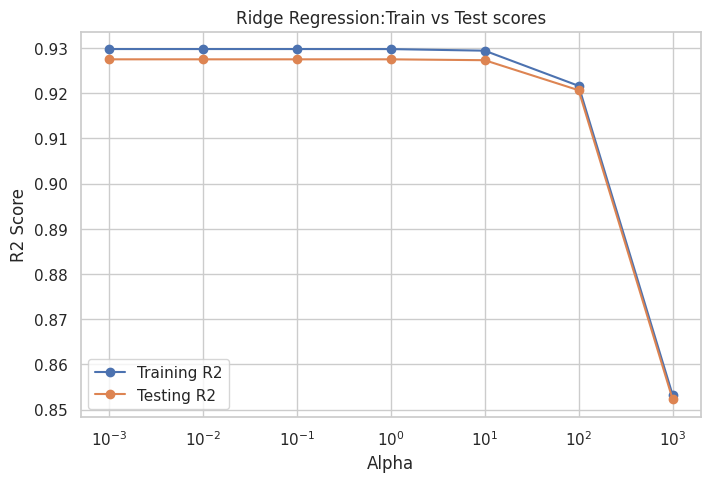

In [37]:
# Plot train and test scores against alpha
plt.figure(figsize=(8,5))
plt.plot(Alphas,train_score,marker='o',label="Training R2")
plt.plot(Alphas,test_score,marker='o',label="Testing R2")
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Ridge Regression:Train vs Test scores')
plt.legend()
plt.grid(True)
plt.show()

Find the best alpha value.

In [38]:
# Best alpha value
best_index = np.argmax(test_score)
best_alpha = Alphas[best_index]
best_ridge_model = ridge_models[best_index]

print("Best alpha value:",best_alpha)
print("Best training R2:",round(train_score[best_index],2))
print("Best testing R2:",round(test_score[best_index],2))
# Best score (negative MAE)
y_test_pred = best_ridge_model.predict(X_test_scaled)
best_mae = mean_absolute_error(y_test,y_test_pred)
print("Best MAE:",round(best_mae,4))

Best alpha value: 0.1
Best training R2: 0.93
Best testing R2: 0.93
Best MAE: 0.0772


In [39]:
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(alphas=np.arange(1, 21, 1),
                   cv=5,
                   scoring='neg_mean_absolute_error')
ridge_cv.fit(X_train_scaled, y_train)

print("Best Ridge alpha (chosen by 5-fold CV):", ridge_cv.alpha_)

Best Ridge alpha (chosen by 5-fold CV): 1


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [40]:
# Take a smaller range of alpha to test
Alphas = np.arange(5,16,1)
print("Alpha values:", Alphas)

Alpha values: [ 5  6  7  8  9 10 11 12 13 14 15]


In [41]:
# Applying Ridge regression
train_score = []
test_score = []
ridge_models =[]
for alpha in Alphas:
  ridge_model = Ridge(alpha=alpha)
  ridge_model.fit(X_train_scaled,y_train)
  ridge_models.append(ridge_model)
  train_score.append(ridge_model.score(X_train_scaled,y_train))
  test_score.append(ridge_model.score(X_test_scaled,y_test))
print("Ridge model trained :",len(ridge_models))


Ridge model trained : 11


Plot the error-alpha graph again and find the actual optimal value for alpha.

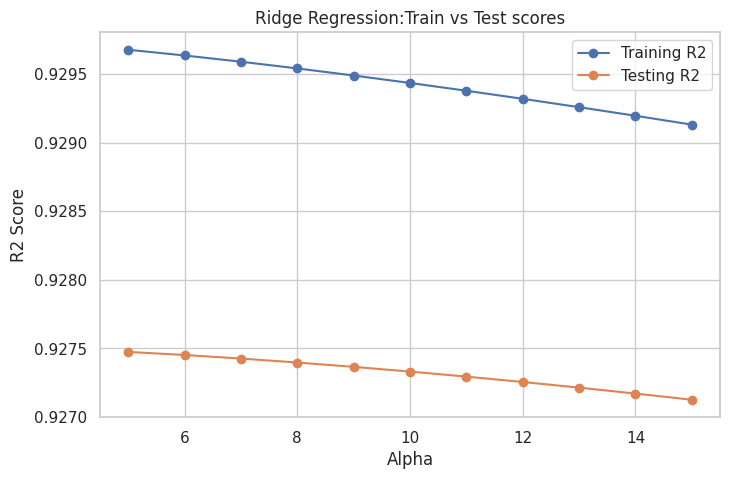

Best alpha value: 5
Best training R2: 0.9297
Best testing R2: 0.9275
Best MAE: 0.0773


In [42]:
# Plot train and test scores against alpha
plt.figure(figsize=(8,5))

plt.plot(Alphas,train_score,marker='o',label="Training R2")
plt.plot(Alphas,test_score,marker='o',label="Testing R2")
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Ridge Regression:Train vs Test scores')
plt.legend()
plt.grid(True)
plt.show()
# Best alpha value
best_index = np.argmax(test_score)
best_alpha = Alphas[best_index]
best_ridge_model = ridge_models[best_index]

print("Best alpha value:",best_alpha)
print("Best training R2:",round(train_score[best_index],4))
print("Best testing R2:",round(test_score[best_index],4))
# Best score (negative MAE)
y_test_pred = best_ridge_model.predict(X_test_scaled)
best_mae = mean_absolute_error(y_test,y_test_pred)
print("Best MAE:",round(best_mae,4))


Ridge Regression was explored with alpha values from 5 to 15, where the test R² was highest at alpha = 5 (train R² 0.9297, test R² 0.9275, MAE 0.0773). To avoid tuning on the test set, the final alpha was chosen by 5-fold cross-validation (RidgeCV) on the training data, which selected alpha = 1 (train R² 0.9298, test R² 0.9275, MAE 0.0773, RMSE 0.1070). The close training and testing R² scores indicate consistent performance on both datasets.

In [43]:
# Set best alpha for Ridge regression
best_alpha =  ridge_cv.alpha_
# Fit the Ridge model to get the coefficients of the fitted model
ridge_final = Ridge(alpha=best_alpha)
ridge_final.fit(X_train_scaled,y_train)

Ridge(alpha=np.int64(1))

In [44]:
# Show the coefficients for each feature
coefficients = pd.DataFrame({'Feature': X_train.columns,
                             'Coefficient': ridge_final.coef_})
display(coefficients.sort_values(by='Coefficient', ascending=False).reset_index(drop=True))

,Feature,Coefficient
0,hp_kW,0.480145
1,make_model_Renault Espace,0.151302
2,Gearing_Type_Semi-automatic,0.108795
3,make_model_Audi A3,0.101275
4,Gears,0.055379
...,...,...
111,age,-0.240289
112,make_model_Other,-0.300819
113,km,-0.316776
114,make_model_Renault Clio,-0.397111


In [45]:
# Evaluate the Ridge model on the test data
y_test_pred = ridge_final.predict(X_test_scaled)
test_mae = mean_absolute_error(y_test, y_test_pred)
print("Test MAE:", round(test_mae, 4))
print("Test R2 Score:",round(r2_score(y_test,y_test_pred),4))
print("Test RMSE:",round(np.sqrt(mean_squared_error(y_test,y_test_pred)),4))

Test MAE: 0.0773
Test R2 Score: 0.9275
Test RMSE: 0.107


### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [46]:
# List of alphas to tune for Lasso regularisation
Alphas = [0.001, 0.01, 0.1, 1, 10, 100,1000]
print("Alpha values:", Alphas)

Alpha values: [0.001, 0.01, 0.1, 1, 10, 100, 1000]


#### **3.3.2** <font color =red> [4 marks] </font>
Apply Lasso Regularisation and find the best value of alpha from the list

In [47]:
# Initialise Lasso regression model
from sklearn.linear_model import Lasso
train_score = []
test_score = []
# train Lasso models for different alpha  values
for alpha in Alphas:
  lasso_model = Lasso(alpha=alpha,max_iter = 10000)
  lasso_model.fit(X_train_scaled,y_train)
  train_score.append(lasso_model.score(X_train_scaled,y_train))
  test_score.append(lasso_model.score(X_test_scaled,y_test))
print("Lasso model trained for all alpha vlaues")
print("Training R2 scores:",[round(score,4) for score in train_score])
print("Testing R2 scores:",[round(score,4) for score in test_score])

Lasso model trained for all alpha vlaues
Training R2 scores: [0.9236, 0.8687, 0.0, 0.0, 0.0, 0.0, 0.0]
Testing R2 scores: [0.9224, 0.8705, -0.0, -0.0, -0.0, -0.0, -0.0]


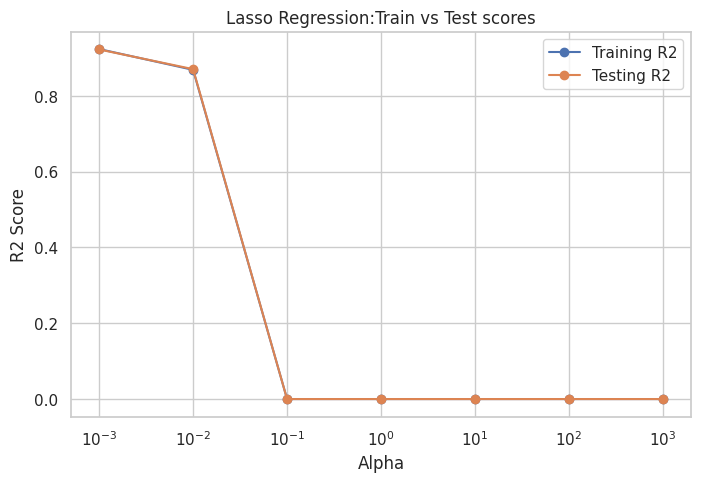

In [48]:
# Plot train and test scores against alpha
plt.figure(figsize=(8,5))
plt.plot(Alphas,train_score,marker='o',label="Training R2")
plt.plot(Alphas,test_score,marker='o',label="Testing R2")
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Lasso Regression:Train vs Test scores')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
from sklearn.model_selection import GridSearchCV

fine_grid = GridSearchCV(
    Lasso(max_iter=10000),
    {'alpha': [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.002, 0.005]},
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1)
fine_grid.fit(X_train_scaled, y_train)

best_alpha = fine_grid.best_params_['alpha']
print("Best Lasso alpha (5-fold CV, fine range):", best_alpha)
print("Best CV score (negative MAE):", round(fine_grid.best_score_, 4))

Best Lasso alpha (5-fold CV, fine range): 5e-05
Best CV score (negative MAE): -0.0792


#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [50]:
# List of alphas to tune for Lasso regularization
Alphas = [0.0001,0.0005,0.001,0.002,0.005,0.01]
print("Fine-Tuning alpha values:",Alphas)

Fine-Tuning alpha values: [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01]


In [51]:
# Tuning Lasso hyperparameters
from sklearn.linear_model import Lasso
train_score = []
test_score = []
# train Lasso models for different alpha  values
for alpha in Alphas:
  Lasso_model = Lasso(alpha=alpha,max_iter = 10000)
  Lasso_model.fit(X_train_scaled,y_train)
  train_score.append(Lasso_model.score(X_train_scaled,y_train))
  test_score.append(Lasso_model.score(X_test_scaled,y_test))
print("Training R2 Scores:",[round(score,4) for score in train_score])
print("Testing R2 Scores:",[round(score,4) for score in test_score])

Training R2 Scores: [0.9296, 0.9268, 0.9236, 0.9178, 0.9025, 0.8687]
Testing R2 Scores: [0.9272, 0.925, 0.9224, 0.9176, 0.9037, 0.8705]


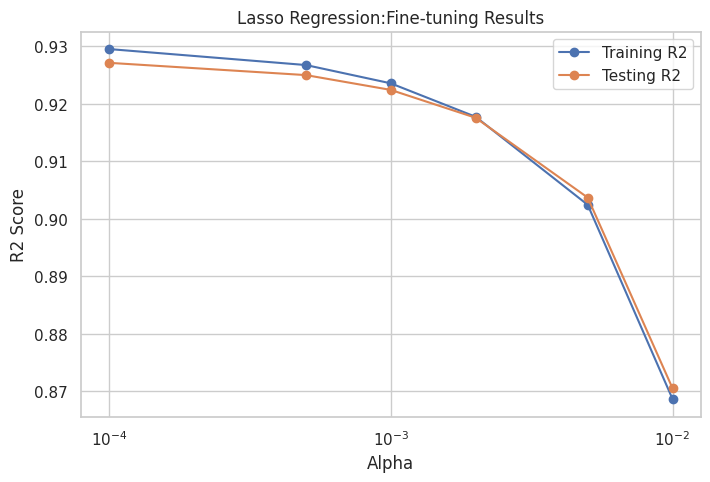

In [52]:
# Plot train and test scores against alpha
plt.figure(figsize=(8,5))
plt.plot(Alphas,train_score,marker='o',label="Training R2")
plt.plot(Alphas,test_score,marker='o',label="Testing R2")
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Lasso Regression:Fine-tuning Results')
plt.legend()
plt.grid(True)
plt.show()

In [53]:
# Best alpha value
best_alpha = fine_grid.best_params_['alpha']
# Best score (negative MAE)
print("Best alpha vlaue:",best_alpha)


Best alpha vlaue: 5e-05


In [54]:
# Set best alpha for Lasso regression
best_alpha = fine_grid.best_params_['alpha']
# Fit the Lasso model on scaled training data
lasso_model = Lasso(alpha=best_alpha, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)

# Get the coefficients of the fitted model
lasso_coefficients = lasso_model.coef_

print("Best alpha:", best_alpha)
print("Lasso model fitted successfully!")
print("Number of coefficients:", len(lasso_coefficients))

Best alpha: 5e-05
Lasso model fitted successfully!
Number of coefficients: 116


In [55]:
# Check the coefficients for each feature
coefficients = pd.DataFrame({'Feature': X_train.columns,
                             'Coefficient': lasso_model.coef_})
display(coefficients.sort_values(by='Coefficient', ascending=False).reset_index(drop=True))

,Feature,Coefficient
0,hp_kW,0.477113
1,make_model_Renault Espace,0.149838
2,Gearing_Type_Semi-automatic,0.107300
3,make_model_Audi A3,0.099808
4,Gears,0.053761
...,...,...
111,age,-0.240811
112,make_model_Other,-0.289748
113,km,-0.316347
114,make_model_Renault Clio,-0.395273


In [56]:
# predict on test data
y_test_pred = lasso_model.predict(X_test_scaled)
# Evaluate the Lasso model on the test data
lasso_mae= mean_absolute_error(y_test, y_test_pred)
lasso_mse = mean_squared_error(y_test, y_test_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, y_test_pred)
print("Lasso Test MAE:", round(lasso_mae, 4))
print("Lasso Test RMSE:", round(lasso_rmse, 4))
print("Lasso Test R2 Score:",round(r2_score(y_test,y_test_pred),4))


Lasso Test MAE: 0.0773
Lasso Test RMSE: 0.1071
Lasso Test R2 Score: 0.9274


### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

In [57]:
# Compare metrics for each model
models = {'Linear Regression': lr_model,
          'Ridge Regression': ridge_final,
          'Lasso Regression': lasso_model}
rows = []
for name, m in models.items():
    p = m.predict(X_test_scaled)
    rows.append({'Model': name,
                 'Train R2': r2_score(y_train, m.predict(X_train_scaled)),
                 'Test R2': r2_score(y_test, p),
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p))})
comparison = pd.DataFrame(rows)
display(comparison.round(4))

,Model,Train R2,Test R2,MAE,RMSE
0,Linear Regression,0.9298,0.9275,0.0772,0.1070
1,Ridge Regression,0.9298,0.9275,0.0773,0.1070
2,Lasso Regression,0.9297,0.9274,0.0773,0.1071


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

In [58]:
# Compare highest coefficients and coefficients of eliminated features
coefficients_comparison = pd.DataFrame({
    'Feature': X_train.columns,
    'Linear Regression': lr_model.coef_,
    'Ridge Regression': ridge_final.coef_,
    'Lasso Regression': lasso_coefficients
})
# display the 10 largest Lasso coefficients by absolute value
coefficients_comparison['Abs_Lasso'] = (coefficients_comparison['Lasso Regression'].abs())
top_features  = coefficients_comparison.sort_values(by='Abs_Lasso',ascending=False).head(10)

print("Top 10 features by absolute Lasso coefficient:")
display(top_features.drop(columns='Abs_Lasso'))
# identify features eliminated by Lasso
eliminated_features = coefficients_comparison[np.isclose(coefficients_comparison['Lasso Regression'],0)]
print("Number of features eliminated by Lasso:",len(eliminated_features))
print("\nFeatures eliminated by Lasso:")
display(eliminated_features[['Feature','Lasso Regression']])

Top 10 features by absolute Lasso coefficient:


,Feature,Linear Regression,Ridge Regression,Lasso Regression
4,hp_kW,0.484755,0.480145,0.477113
11,make_model_Opel Corsa,-0.436327,-0.434748,-0.434549
14,make_model_Renault Clio,-0.399389,-0.397111,-0.395273
0,km,-0.317514,-0.316776,-0.316347
13,make_model_Other,-0.324739,-0.300819,-0.289748
2,age,-0.240248,-0.240289,-0.240811
10,make_model_Opel Astra,-0.220306,-0.218340,-0.217984
15,make_model_Renault Espace,0.150394,0.151302,0.149838
30,Gearing_Type_Manual,-0.116557,-0.116666,-0.117736
31,Gearing_Type_Semi-automatic,0.108847,0.108795,0.107300


Number of features eliminated by Lasso: 7

Features eliminated by Lasso:


,Feature,Lasso Regression
27,Paint_Type_Other,0.0
32,Drive_chain_Other,-0.0
59,Comfort_Convenience_Rain sensor,-0.0
87,Extras_Winter tyres,-0.0
90,Safety_Security_Adaptive headlights,-0.0
96,Safety_Security_Driver drowsiness detection,0.0
114,Safety_Security_Traffic sign recognition,-0.0


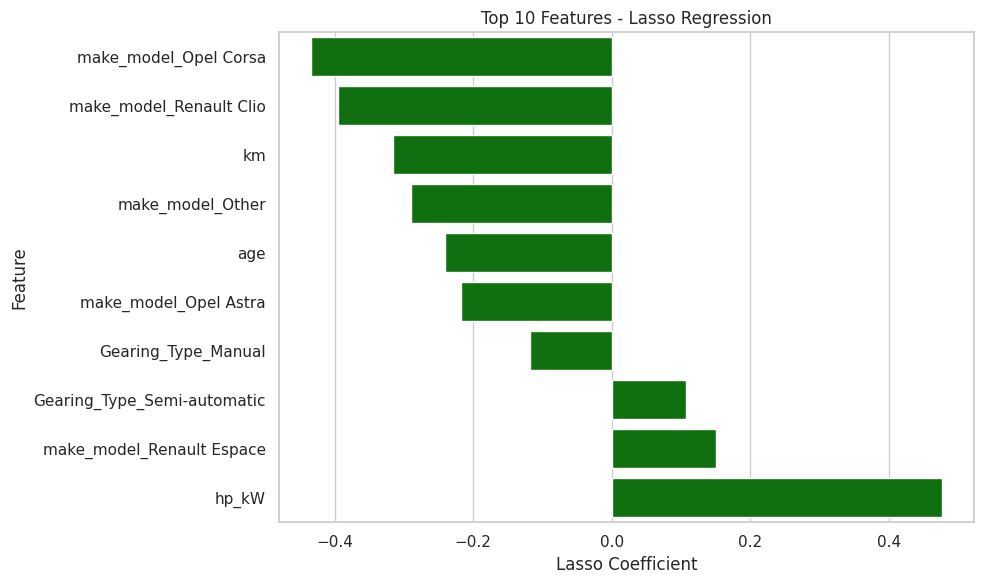

In [59]:
# Plot top 10 features by absolute Lasso coefficient
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features.sort_values('Lasso Regression'),
    x='Lasso Regression',
    y='Feature',
    color = 'green'
)

plt.title('Top 10 Features - Lasso Regression')
plt.xlabel('Lasso Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

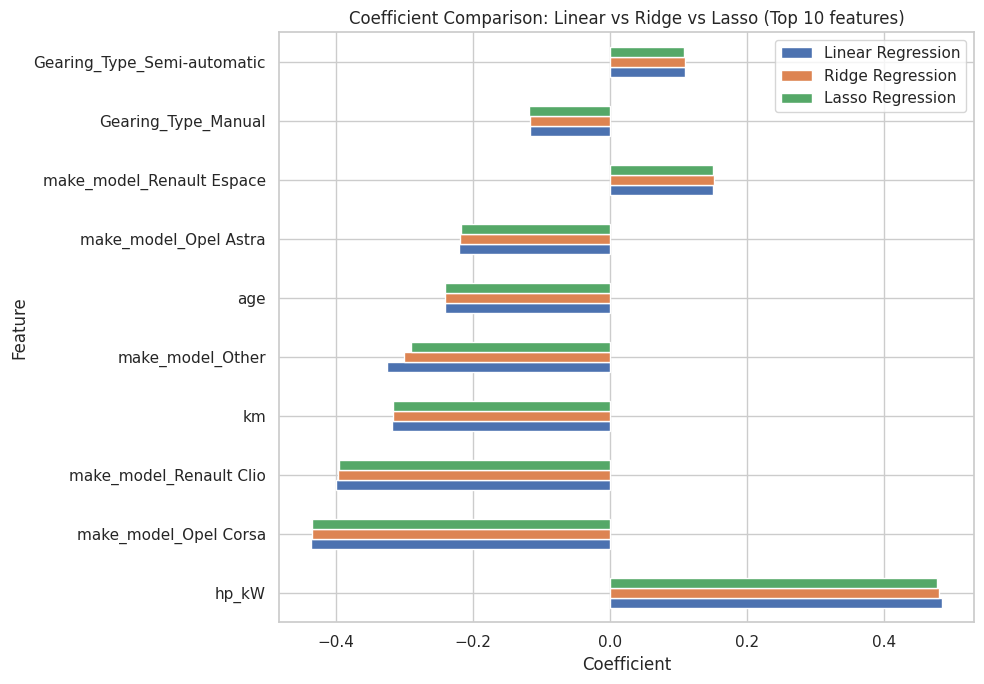

In [60]:
# Compare top coefficients of Linear, Ridge and Lasso
top = top_features.drop(columns='Abs_Lasso').set_index('Feature')
top.plot(kind='barh', figsize=(10, 7))
plt.title('Coefficient Comparison: Linear vs Ridge vs Lasso (Top 10 features)')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()

In [61]:
print("Number of features eliminated by Lasso:", len(eliminated_features))
print("Number of features retained:", len(coefficients_comparison) - len(eliminated_features))
print("Best Lasso alpha:", best_alpha)
display(eliminated_features[['Feature', 'Linear Regression', 'Ridge Regression']].head(20))

Number of features eliminated by Lasso: 7
Number of features retained: 109
Best Lasso alpha: 5e-05


,Feature,Linear Regression,Ridge Regression
27,Paint_Type_Other,0.010581,0.009322
32,Drive_chain_Other,-0.041529,-0.029422
59,Comfort_Convenience_Rain sensor,-0.001099,-0.000931
87,Extras_Winter tyres,0.000250,0.000255
90,Safety_Security_Adaptive headlights,0.000121,0.000118
96,Safety_Security_Driver drowsiness detection,-0.000056,-0.000010
114,Safety_Security_Traffic sign recognition,-0.000170,-0.000307


The coefficients of Linear Regression, Ridge Regression, and Lasso Regression were compared. All three models give very similar coefficients. `hp_kW` has the largest positive coefficient, while `make_model_Opel Corsa` and `make_model_Renault Clio` have strong negative coefficients. `km` and `age` are also negative, indicating that higher mileage and older vehicle age are associated with lower predicted prices, holding other features constant. Manual gearing lowers price, while semi-automatic gearing raises it.

Ridge shrank the coefficients slightly towards zero, most visibly for `make_model_Other`. Lasso (alpha = 5e-05, chosen by 5-fold cross-validation) set 7 of the 116 coefficients to exactly zero and retained 109. The eliminated features are `Paint_Type_Other`, `Drive_chain_Other`, `Comfort_Convenience_Rain sensor`, `Extras_Winter tyres`, `Safety_Security_Adaptive headlights`, `Safety_Security_Driver drowsiness detection` and `Safety_Security_Traffic sign recognition`. These are rare categories or equipment flags whose coefficients were already close to zero in Linear and Ridge, so they contribute almost nothing to price prediction.

## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>

### Conclusion and Key Takeaways

In this project, Linear Regression, Ridge Regression, and Lasso Regression were used to predict used-car prices. The target (price) was log-transformed to reduce skewness, outliers were capped using the IQR method, duplicate rows were removed, and categorical and multi-value feature columns were encoded before modelling.

**1. Model Performance Comparison**

| Model | Train R2 | Test R2 | MAE | RMSE |
|---|---|---|---|---|
| Linear Regression | 0.9298 | 0.9275 | 0.0772 | 0.1070 |
| Ridge (alpha = 1, 5-fold CV) | 0.9298 | 0.9275 | 0.0773 | 0.1070 |
| Lasso (alpha = 5e-05, 5-fold CV) | 0.9297 | 0.9274 | 0.0773 | 0.1071 |

All three models perform almost identically. The differences are in the fourth decimal place and are not practically meaningful. Errors are on the log-price scale, so an MAE of about 0.077 corresponds to roughly 8% average error in price.

**2. Effect of Regularisation**

Regularisation did not improve performance. Ridge matched Linear Regression, and Lasso was 0.0001 lower in test R2. The reason is that the baseline model was not overfitting, so there was no extra variance for regularisation to remove. Ridge shrank the coefficients of correlated features slightly, and Lasso removed 7 of 116 features, which are rare categories with almost no effect on price.

**3. Overfitting Analysis**

Training and test R2 are close for all models (about 0.930 vs 0.9275, a gap of about 0.002), so there is no meaningful overfitting. The training set has 11,390 rows for 116 features, which is large enough to estimate the parameters reliably. Cross-validation also chose very small alpha values (1 for Ridge and 5e-05 for Lasso), which shows that the data needed very little regularisation. Stronger Lasso penalties (alpha 0.001 or more) remove more features but reduce accuracy.

**4. Was the Data Sufficient?**

Yes, for this purpose. After removing duplicates there were 14,238 records, and the models explain about 92.7% of the variance in log-price on unseen data. The remaining error may come from information not in the dataset, such as exact trim level, car condition, location and listing date.

**5. Was a Linear Model Sufficient?**

A linear model is a strong and interpretable baseline, since it reaches R2 of about 0.93. The residual plot shows no strong curve, but the spread of residuals changes slightly across predicted prices, so some non-linear effects and interactions (for example age with make) may exist. Tree-based models or added interaction terms could be tested to see if accuracy improves.

**Key insights:** engine power (hp_kW) increases price the most, while mileage (km), age and cheaper models (Opel Corsa, Renault Clio, Opel Astra) reduce it. Manual gearing lowers price, and semi-automatic raises it.

**Final Conclusion:** Linear, Ridge and Lasso Regression perform equally well on this dataset (test R2 about 0.9275), and the model does not overfit. Regularisation mainly gave slightly more stable coefficients and a little feature selection rather than a gain in accuracy. Any of the three models is suitable. Ridge or Lasso is preferable for safety against multicollinearity, and Lasso gives a slightly simpler model.